# Notebook 5 – Bivariate Analysis

Bivariate analysis is a statistical technique used to study the relationship between two variables in a dataset. It helps us understand whether two variables are related, how they change together, and whether differences exist between categories.

For example:

- Age vs Salary: Does salary increase as age increases?
- Income vs Spending: Do people with higher incomes spend more?
- Department vs Salary: Does average salary differ between departments?
- Product Category vs Sales: Which product categories generate higher sales?
  
Why is Bivariate Analysis important?

- Identifies relationships between variables
- Helps discover patterns and trends
- Supports business decision-making
- Helps identify potentially useful features for machine learning
- Helps us decide which variables need further investigation

Types of Bivariate Analysis

Variable 1	  Variable 2	            Example	                       Recommended techniques

Numerical	  Numerical	        Age vs Salary	                   Scatter plot, correlation

Numerical	 Categorical	   Department vs Salary	               Box plot, violin plot

Categorical	 Categorical	  Department vs ProductCategory	       Cross-tabulation, grouped bar chart

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Age": [22, 25, 28, 32, 35, 38, 42, 45, 26, 31, 36, 40],
    "Salary": [25000, 30000, 35000, 42000, 48000, 52000,
               60000, 65000, 32000, 40000, 50000, 58000],
    "Income": [30000, 35000, 40000, 50000, 55000, 60000,
               70000, 75000, 38000, 48000, 58000, 68000],
    "Spending": [12000, 15000, 18000, 22000, 26000, 28000,
                 35000, 38000, 17000, 21000, 27000, 32000],
    "Department": ["IT", "HR", "IT", "Sales", "HR", "IT",
                   "Sales", "IT", "HR", "Sales", "IT", "Sales"],
    "Product_Category": ["Electronics", "Clothing", "Food", "Electronics",
                         "Clothing", "Food", "Electronics", "Clothing",
                         "Food", "Electronics", "Clothing", "Food"],
    "Sales": [50000, 25000, 18000, 65000, 30000, 22000,
              80000, 35000, 20000, 60000, 32000, 25000]
})

df.head()

,Age,Salary,Income,Spending,Department,Product_Category,Sales
0,22,25000,30000,12000,IT,Electronics,50000
1,25,30000,35000,15000,HR,Clothing,25000
2,28,35000,40000,18000,IT,Food,18000
3,32,42000,50000,22000,Sales,Electronics,65000
4,35,48000,55000,26000,HR,Clothing,30000


## Numerical vs Numerical

In [ ]:
This analysis examines the relationship between two numerical variables

Examples:

- Age vs Salary
- Income vs Spending
- Advertising Cost vs Sales Revenue

Technique 1: Scatter Plot

A scatter plot displays individual observations as points on a graph

- X-axis: First numerical variable
- Y-axis: Second numerical variable
- Each point: One observation

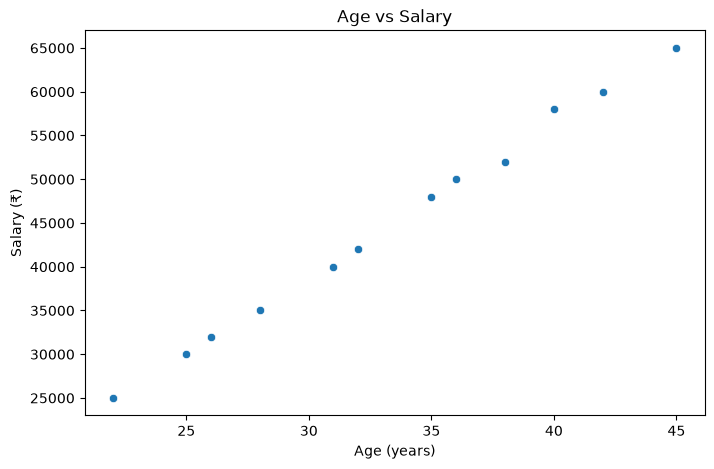

In [2]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Age", y="Salary")

plt.title("Age vs Salary")
plt.xlabel("Age (years)")
plt.ylabel("Salary (₹)")
plt.show()

How to interpret the scatter plot:

Positive relationship:

As one variable increases, the other tends to increase. For example, older employees may earn higher salaries.


Neative relationship:

As one variable increases, the other tends to decrease. For example, product price may increase while demand decreases.

No clear linear relationship:

Points do not show a clear upward or downward pattern.


Finding from our example: Age and salary show a positive relationship in the sample dataset. Older employees generally have higher salaries, although this does not prove that age causes a salary increase.

### Technique 2: Correlation

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Pearson's correlation coefficient ranges from \(-1\) to \(+1\)

In [3]:
correlation = df["Age"].corr(df["Salary"])

print("Correlation:", round(correlation, 3))

Correlation: 0.999


In [ ]:
Interpretation:

- Close to +1: Strong positive linear relationship
- Close to -1: Strong negative linear relationship
- Close to 0: Weak or no linear relationship

A correlation near zero does not necessarily mean that no relationship exists; the relationship could be nonlinear

## Numerical vs Categorical

This analysis compares a numerical variable across categories

Examples:

- Department vs Salary
- Product Category vs Sales
- Education Level vs Income
  
### Technique 1: Box Plot

A box plot compares the distribution of a numerical variable across categories. It shows the median, quartiles, spread and potential outliers.

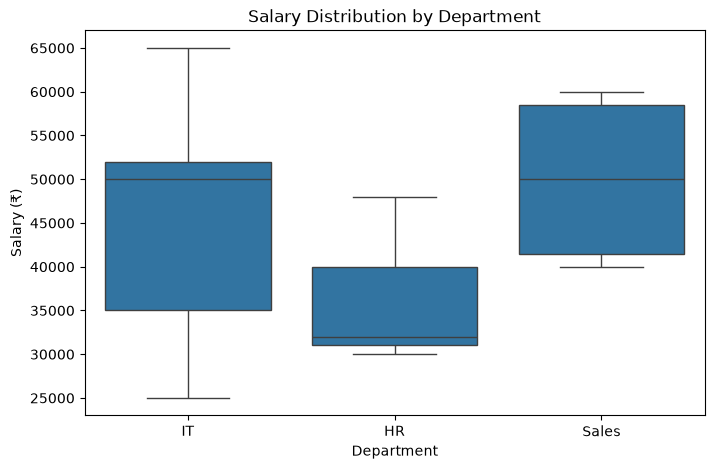

In [4]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Department", y="Salary")

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary (₹)")
plt.show()

How to interpret a box plot

- Median: The middle salary in each department
- Box: The middle 50% of salary values, between Q1 and Q3
- Whiskers: The range of observations within the plot's outlier rule
- Points outside whiskers: Potential outliers, not necessarily errors
- Box height: The variability of salaries within the department

Finding: Compare the median salary of IT, HR and Sales to determine which department has the highest typical salary. 
    A wider box indicates greater variability in the middle 50% of salaries.

### Technique 2: Violin Plot

A violin plot shows the distribution and density of numerical values within each category

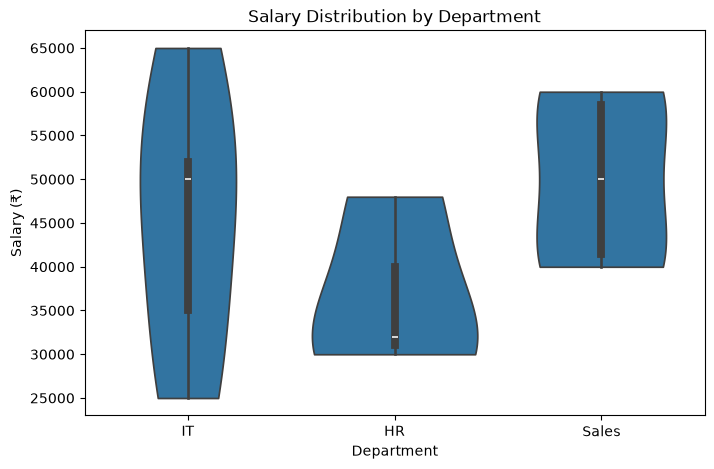

In [5]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="Department",
    y="Salary",
    inner="box",
    cut=0
)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary (₹)")
plt.show()

How to interpret it:

- Wider sections indicate a higher concentration of observations at those values
- Narrower sections indicate a lower concentration
- Different shapes may indicate different salary distributions
- The inner box provides a reference for the median and quartiles
  
Finding: If one department's violin is concentrated at higher salaries, that department tends to have higher salaries in the sample. Since our dataset is small, treat the density shape as illustrative rather than conclusive.

### Technique 3: Grouped summary statistics

Before plotting, calculate salary statistics by department

In [6]:
department_summary = df.groupby("Department")["Salary"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(department_summary.round(2))

            count      mean   median    min    max
Department                                        
HR              3  36666.67  32000.0  30000  48000
IT              5  45400.00  50000.0  25000  65000
Sales           4  50000.00  50000.0  40000  60000


Finding: The summary identifies which department has the highest mean salary and which has the highest median salary. Comparing both is useful because the mean can be affected by unusually high or low values

## Categorical vs Categorical

This analysis examines relationships between two categorical variables

Examples:

- Department vs Gender
- Product Category vs Payment Method
- Customer Type vs Purchase Status

### Technique 1: Cross-Tabulation

Cross-tabulation, also called a contingency table, counts observations for each combination of two categorical variables.

In [7]:
cross_tab = pd.crosstab(
    df["Department"],
    df["Product_Category"]
)

print(cross_tab)

Product_Category  Clothing  Electronics  Food
Department                                   
HR                       2            0     1
IT                       2            1     2
Sales                    0            3     1


How to interpret the output:

- Rows represent departments
- Columns represent product categories
- Each cell represents the number of observations belonging to that combination
- 
For example, the table helps answer questions such as:

- Which department appears most frequently with Electronics?
- Which product category is most common in HR?
- Are some combinations more frequent than others?
- 
Our dataset is illustrative, so these counts describe only the 12 records provided

### Technique 2: Grouped Bar Chart

A grouped bar chart compares category counts side by side

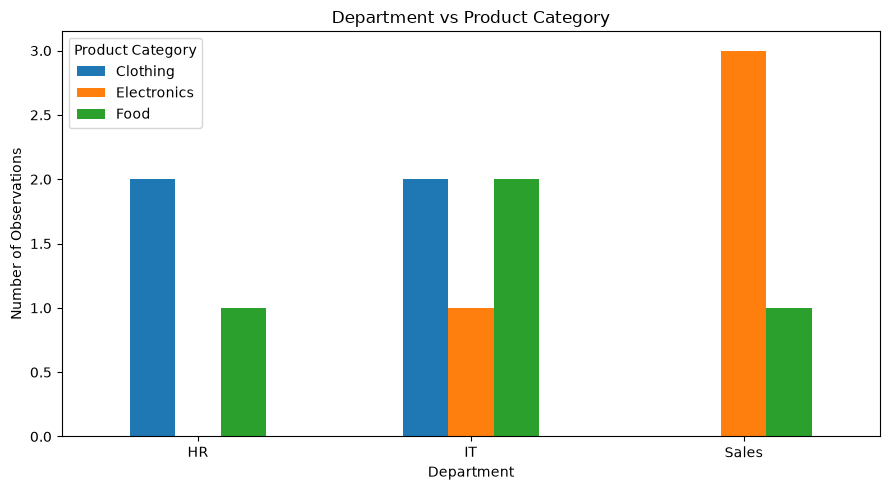

In [8]:
cross_tab.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Department vs Product Category")
plt.xlabel("Department")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

How to interpret the chart:

- Each group represents a department
- Each bar represents a product category
- Taller bars represent more observations
- Differences in bar heights reveal which combinations are more frequent
- 
Finding: If Electronics has the tallest bar within a department, Electronics is the most frequent product category for that department in the sample. However, frequency alone does not indicate revenue or profitability

### Technique 3: Percentage Cross-Tabulation

Percentages can make category comparisons easier when group sizes differ

In [9]:
percentage_table = pd.crosstab(
    df["Department"],
    df["Product_Category"],
    normalize="index"
) * 100

print(percentage_table.round(2))

Product_Category  Clothing  Electronics   Food
Department                                    
HR                   66.67          0.0  33.33
IT                   40.00         20.0  40.00
Sales                 0.00         75.0  25.00


Formula for the percentage within each row:

Percentage within each row:

$$
\text{Percentage} =
\frac{\text{Cell Frequency}}{\text{Row Total}} \times 100
$$

Interpretation: Each department's percentages sum to 100%. This lets us compare the composition of product categories across departments, rather than simply comparing raw counts

### Age vs Salary:

Variables: Age (Numerical), Salary (Numerical)

Observation: The scatter plot shows a positive relationship between age and salary in our sample dataset. As age increases, salary generally increases.

Interpretation:

- Older employees tend to earn higher salaries in these observations
- This may be associated with work experience, skills, or seniority
- However, age alone does not determine salary
  
Conclusion: Age and salary have a positive relationship in the sample dataset

### Income vs Spending
   
Variables: Income (Numerical), Spending (Numerical)

Observation: People with higher incomes generally have higher spending values in our sample dataset.

Interpretation:

- Higher-income customers may have more money available for purchases.
- Businesses can study this relationship to understand customer purchasing behavior
- Higher income does not always mean higher spending because saving habits and personal preferences also matter
  
Conclusion: Income and spending show a positive relationship in the sample dataset

### Department vs Salary

Variables: Department (Categorical), Salary (Numerical)

Observation: The box plot shows differences in salary distributions across IT, HR, and Sales departments.

Interpretation:

- Compare the median salary of each department to identify which has the highest typical salary
- A wider box indicates greater variability in the middle 50% of salaries
- Salary differences may reflect job roles, experience, and responsibilities
  
Conclusion: Salary distributions vary across departments in the sample dataset. Comparing medians and spreads helps identify these differences

### Product Category vs Sales
   
Variables: Product Category (Categorical), Sales (Numerical)

Observation: The bar chart compares total sales across Electronics, Clothing, and Food.

Interpretation:

- The category with the highest total sales contributes the most revenue in this dataset
- The category with the lowest total sales may need further investigation
- Businesses can use these findings to support inventory planning and marketing decisions
  
Conclusion: Total sales vary across product categories. The category with the highest total sales is the strongest revenue contributor in this sample.